# Sistem Rekomendasi Film Menggunakan Content-Based Filtering
# Dataset: TMDB 5000 Movies & Credits
# Nama: [Salman Alfarizi Taha]
# Cohort ID: [MC009D5Y0777]



PROJECT OVERVIEW

Latar Belakang:
Dengan berkembangnya platform streaming dan database film yang besar, pengguna seringkali
kesulitan menemukan film yang sesuai dengan preferensi mereka. Sistem rekomendasi film
dapat membantu pengguna menemukan film-film baru berdasarkan kesamaan konten dengan film
yang mereka sukai.

Tujuan:
Membangun sistem rekomendasi film menggunakan pendekatan Content-Based Filtering yang dapat
merekomendasikan film berdasarkan kesamaan fitur konten seperti genre, kata kunci,
pemeran utama, dan sutradara.



# BUSINESS UNDERSTANDING





Problem Statements:
1. Bagaimana cara membantu pengguna menemukan film yang sesuai dengan preferensi mereka
   berdasarkan film yang pernah mereka tonton dan sukai?
2. Bagaimana mengukur kemiripan antar film berdasarkan konten seperti genre, cast,
   director, dan keywords?
3. Bagaimana membangun sistem yang dapat memberikan rekomendasi yang relevan dan beragam?

Goals:
1. Membangun sistem rekomendasi yang akurat berdasarkan konten film
2. Menghasilkan rekomendasi yang relevan dengan similarity score tinggi (>0.1)
3. Menyediakan sistem evaluasi untuk mengukur performa rekomendasi
4. Mencapai precision minimal 70% untuk film dengan rating di atas 7.0

Solution Approach:
Menggunakan Content-Based Filtering dengan TF-IDF atau Count Vectorizer untuk ekstraksi
fitur dan Cosine Similarity untuk menghitung kemiripan antar film.

# IMPORT PACKAGE

In [3]:
!pip install wordcloud

In [4]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

# Set style untuk visualisasi
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# DATA UNDERSTANDING





Dataset yang digunakan adalah TMDB 5000 Movies yang terdiri dari:
- tmdb_5000_movies.csv: Informasi detail film (budget, genres, overview, dll)
- tmdb_5000_credits.csv: Informasi cast dan crew

Fitur Utama yang akan digunakan:
- Genres: Kategori film (Action, Drama, Comedy, dll)
- Keywords: Kata kunci yang mendeskripsikan tema/plot film
- Cast: Pemeran utama film (top 3)
- Director: Sutradara film
- Vote Average: Rating film dari pengguna
- Vote Count: Jumlah vote yang diterima film


In [5]:
# Load Datasets dengan error handling
try:
    movies_df = pd.read_csv(
        'tmdb_5000_movies.csv',
        engine='python',
        on_bad_lines='skip'
    )
    print(f"✅ Movies dataset berhasil dimuat: {len(movies_df)} film")

    credits_df = pd.read_csv(
        'tmdb_5000_credits.csv',
        engine='python',
        on_bad_lines='skip'
    )
    print(f"✅ Credits dataset berhasil dimuat: {len(credits_df)} film")

except FileNotFoundError as e:
    print(f"❌ Error: File tidak ditemukan - {e}")
    print("Pastikan file tmdb_5000_movies.csv dan tmdb_5000_credits.csv berada di direktori yang sama")
    exit()


✅ Movies dataset berhasil dimuat: 4803 film
✅ Credits dataset berhasil dimuat: 4803 film


In [6]:
# Data Understanding - Exploratory Data Analysis
print("\n" + "=" * 50)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 50)

print("\n📊 INFORMASI DATASET MOVIES:")
print(f"Shape: {movies_df.shape}")
print(f"Kolom: {list(movies_df.columns)}")

print("\n📊 INFORMASI DATASET CREDITS:")
print(f"Shape: {credits_df.shape}")
print(f"Kolom: {list(credits_df.columns)}")

# Cek missing values
print("\n📋 MISSING VALUES - MOVIES:")
missing_movies = movies_df.isnull().sum()
print(missing_movies[missing_movies > 0])

print("\n📋 MISSING VALUES - CREDITS:")
missing_credits = credits_df.isnull().sum()
print(missing_credits[missing_credits > 0])

# Statistik deskriptif
print("\n📈 STATISTIK DESKRIPTIF:")
print(movies_df[['budget', 'revenue', 'runtime', 'vote_average', 'vote_count']].describe())



EXPLORATORY DATA ANALYSIS

📊 INFORMASI DATASET MOVIES:
Shape: (4803, 20)
Kolom: ['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

📊 INFORMASI DATASET CREDITS:
Shape: (4803, 4)
Kolom: ['movie_id', 'title', 'cast', 'crew']

📋 MISSING VALUES - MOVIES:
homepage        3091
overview           3
release_date       1
runtime            2
tagline          844
dtype: int64

📋 MISSING VALUES - CREDITS:
Series([], dtype: int64)

📈 STATISTIK DESKRIPTIF:
             budget       revenue      runtime  vote_average    vote_count
count  4.803000e+03  4.803000e+03  4801.000000   4803.000000   4803.000000
mean   2.904504e+07  8.226064e+07   106.875859      6.092172    690.217989
std    4.072239e+07  1.628571e+08    22.611935      1.194612   1234.585891
min    0.000000e+00 

Menggabungkan Dataset tmdb_5000_movies.csv dan tmdb_5000_credits.csv

In [7]:
# Merge datasets
movies_df = movies_df.merge(
    credits_df,
    left_on='id',
    right_on='movie_id',
    how='left'
)

print(f"✅ Dataset berhasil digabung: {len(movies_df)} film")
print(f"Kolom setelah merge: {len(movies_df.columns)} kolom")

# Add this line to check the column names after merge
print("\nKolom setelah merge:")
print(movies_df.columns)

✅ Dataset berhasil digabung: 4803 film
Kolom setelah merge: 24 kolom

Kolom setelah merge:
Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title_x', 'vote_average',
       'vote_count', 'movie_id', 'title_y', 'cast', 'crew'],
      dtype='object')


# DATA VISUALIZATION

membuat empat visualisasi utama:

1. Histogram distribusi rating film

2. Histogram distribusi tahun rilis

3. Scatter plot antara runtime dan rating

4. Bar chart 10 film dengan rating tertinggi

Tujuannya adalah memahami karakteristik data yang akan digunakan


📊 MEMBUAT VISUALISASI...


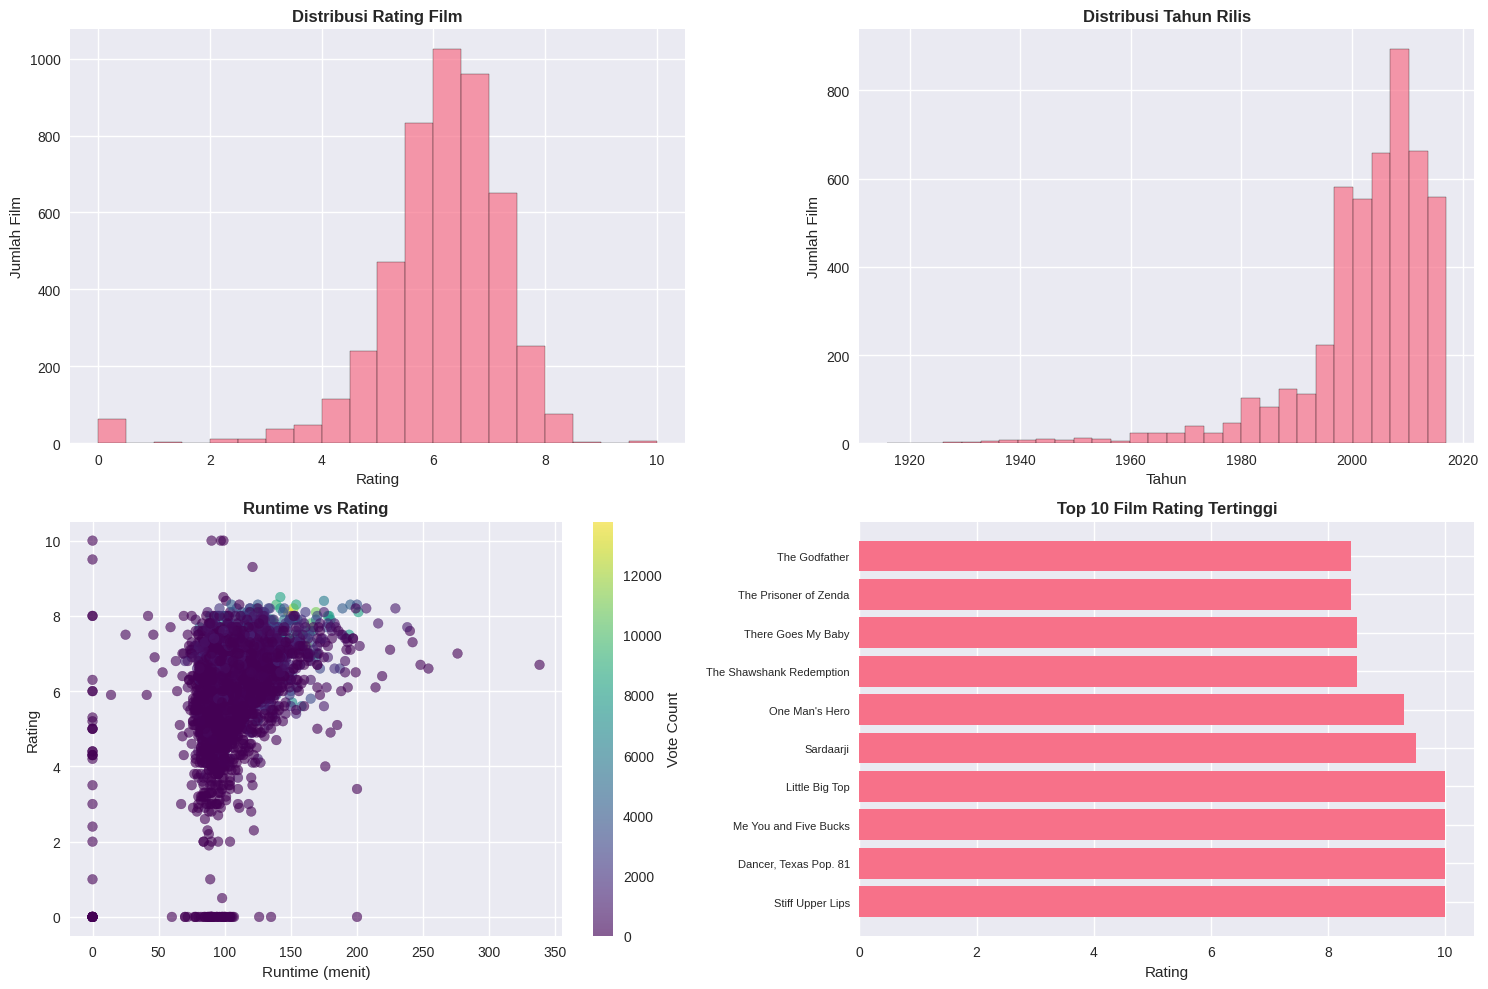

In [8]:
# Visualisasi Data
print("\n📊 MEMBUAT VISUALISASI...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Distribusi Rating
axes[0, 0].hist(movies_df['vote_average'], bins=20, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribusi Rating Film', fontsize=12, weight='bold')
axes[0, 0].set_xlabel('Rating')
axes[0, 0].set_ylabel('Jumlah Film')

# Plot 2: Distribusi Tahun Rilis
movies_df['release_year'] = pd.to_datetime(movies_df['release_date'], errors='coerce').dt.year
movies_df['release_year'].hist(bins=30, edgecolor='black', alpha=0.7, ax=axes[0, 1])
axes[0, 1].set_title('Distribusi Tahun Rilis', fontsize=12, weight='bold')
axes[0, 1].set_xlabel('Tahun')
axes[0, 1].set_ylabel('Jumlah Film')

# Plot 3: Runtime vs Rating
scatter = axes[1, 0].scatter(movies_df['runtime'], movies_df['vote_average'],
                           alpha=0.6, c=movies_df['vote_count'], cmap='viridis')
axes[1, 0].set_title('Runtime vs Rating', fontsize=12, weight='bold')
axes[1, 0].set_xlabel('Runtime (menit)')
axes[1, 0].set_ylabel('Rating')
plt.colorbar(scatter, ax=axes[1, 0], label='Vote Count')

# Plot 4: Top 10 Film dengan Rating Tertinggi
top_rated = movies_df.nlargest(10, 'vote_average')[['title_x', 'vote_average']]
axes[1, 1].barh(range(len(top_rated)), top_rated['vote_average'])
axes[1, 1].set_yticks(range(len(top_rated)))
axes[1, 1].set_yticklabels(top_rated['title_x'], fontsize=8)
axes[1, 1].set_title('Top 10 Film Rating Tertinggi', fontsize=12, weight='bold')
axes[1, 1].set_xlabel('Rating')

plt.tight_layout()
plt.show()


# FEATURE ENGINEERING

Membuat fungsi parse_json_column untuk mengekstrak nilai name dari kolom berisi data JSON string. Ini diterapkan pada kolom genres dan keywords. Untuk cast, hanya mengambil 3 pemeran utama, dan untuk crew, hanya nama sutradara yang diambil.



In [9]:
# Fungsi bantu untuk parsing JSON
def parse_json_column(json_str):
    """
    Memparsing string JSON dan mengembalikan list elemen 'name'.
    Jika parsing gagal, kembalikan list kosong.
    """
    try:
        data = json.loads(json_str)
        if isinstance(data, list):
            names = [d.get('name', '') for d in data if isinstance(d, dict) and 'name' in d]
            return names
    except (TypeError, json.JSONDecodeError, AttributeError):
        pass
    return []




Pada tahap ini, dilakukan proses ekstraksi fitur dari beberapa kolom penting yang menyimpan data dalam format JSON string, yaitu `genres`, `keywords`, `cast`, dan `crew`. Karena kolom-kolom ini tidak dapat langsung digunakan dalam bentuk mentah, maka dilakukan parsing untuk mengambil informasi relevan.

**1. Genres**  
Kolom `genres` menyimpan informasi kategori film (seperti Action, Drama, dsb.) dalam bentuk list of dictionaries. Dengan fungsi `parse_json_column`, sistem mengekstrak semua nama genre menjadi list of strings agar bisa diproses lebih lanjut.

**2. Keywords**  
Kolom `keywords` juga berisi list of dictionaries yang merepresentasikan kata kunci atau tema utama dari film. Kata-kata ini sangat penting karena menggambarkan konten inti dari sebuah film.

**3. Cast (Pemeran Utama)**  
Informasi pemain film tersimpan di kolom `cast` dalam format JSON. Dari data tersebut, hanya tiga pemeran utama (top 3 berdasarkan urutan tampil) yang diambil menggunakan fungsi `get_top_cast`. Pemain utama dapat sangat memengaruhi minat pengguna terhadap suatu film.

**4. Director (Sutradara)**  
Kolom `crew` mencakup semua kru film. Di sini, hanya data dengan peran sebagai `Director` yang diambil karena sutradara berkontribusi besar terhadap gaya dan kualitas sebuah film. Pengambilan dilakukan dengan fungsi `get_director`.

Setiap hasil ekstraksi disimpan ke dalam kolom baru dalam bentuk list dan akan digunakan untuk membuat representasi teks film (*content soup*) pada tahap selanjutnya.


In [10]:
# Ekstraksi fitur konten
print("🔧 Mengekstrak fitur dari kolom JSON...")

# 7.1. Genres
movies_df['genres_list'] = movies_df['genres'].apply(parse_json_column)
print(f"✅ Genres diekstrak untuk {len(movies_df[movies_df['genres_list'].str.len() > 0])} film")

# 7.2. Keywords
movies_df['keywords_list'] = movies_df['keywords'].apply(parse_json_column)
print(f"✅ Keywords diekstrak untuk {len(movies_df[movies_df['keywords_list'].str.len() > 0])} film")

# 7.3. Cast (ambil top 3)
def get_top_cast(cast_json_str, top_n=3):
    """Mengambil nama cast utama berdasarkan order"""
    try:
        cast_data = json.loads(cast_json_str)
        if isinstance(cast_data, list):
            # Sort berdasarkan order, ambil top N
            cast_data_sorted = sorted(cast_data, key=lambda d: d.get('order', float('inf')))
            top_cast = [d.get('name', '') for d in cast_data_sorted[:top_n]
                       if isinstance(d, dict) and 'name' in d]
            return top_cast
    except (TypeError, json.JSONDecodeError, AttributeError):
        pass
    return []

movies_df['cast_list'] = movies_df['cast'].apply(lambda x: get_top_cast(x, top_n=3))
print(f"✅ Cast diekstrak untuk {len(movies_df[movies_df['cast_list'].str.len() > 0])} film")

# 7.4. Director
def get_director(crew_json_str):
    """Mengambil nama director dari crew"""
    try:
        crew_data = json.loads(crew_json_str)
        if isinstance(crew_data, list):
            directors = [d.get('name', '') for d in crew_data
                        if isinstance(d, dict) and d.get('job') == 'Director' and 'name' in d]
            return directors
    except (TypeError, json.JSONDecodeError, AttributeError):
        pass
    return []

movies_df['director_list'] = movies_df['crew'].apply(get_director)
print(f"✅ Director diekstrak untuk {len(movies_df[movies_df['director_list'].str.len() > 0])} film")

🔧 Mengekstrak fitur dari kolom JSON...
✅ Genres diekstrak untuk 4775 film
✅ Keywords diekstrak untuk 4391 film
✅ Cast diekstrak untuk 4760 film
✅ Director diekstrak untuk 4773 film


# DATA PROCESSING

Setelah fitur-fitur konten seperti `genres`, `keywords`, `cast`, dan `director` berhasil diekstrak dalam bentuk list of strings, tahap selanjutnya adalah melakukan pembersihan data agar siap digunakan dalam model.

Proses *text preprocessing* ini mencakup:
- Mengubah seluruh teks menjadi huruf kecil (lowercase)
- Menghapus spasi dalam setiap elemen list
- Menghilangkan string kosong atau tidak valid

Tujuan dari pembersihan ini adalah untuk menyamakan format kata-kata yang akan digunakan dalam proses vektorisasi, sehingga kata-kata seperti "Science Fiction" dan "sciencefiction" tidak dianggap berbeda oleh model. Hasil pembersihan disimpan dalam kolom baru `*_clean`, yaitu `genres_clean`, `keywords_clean`, `cast_clean`, dan `director_clean`.

Langkah ini merupakan bagian penting dalam Content-Based Filtering karena hasil akhir dari teks ini akan menjadi representasi konten (content representation) dari setiap film.


In [11]:
# Text Preprocessing
print("\n🔧 Preprocessing teks...")

def clean_list(input_list):
    """
    Membersihkan list of strings: lowercase, hapus spasi, filter string kosong
    """
    if not isinstance(input_list, list):
        return []

    cleaned = []
    for item in input_list:
        if isinstance(item, str) and item.strip():
            # Hapus spasi dan ubah ke lowercase
            token = item.replace(" ", "").lower()
            cleaned.append(token)
    return cleaned

# Apply cleaning
movies_df['genres_clean'] = movies_df['genres_list'].apply(clean_list)
movies_df['keywords_clean'] = movies_df['keywords_list'].apply(clean_list)
movies_df['cast_clean'] = movies_df['cast_list'].apply(clean_list)
movies_df['director_clean'] = movies_df['director_list'].apply(clean_list)

print("✅ Text preprocessing selesai")



🔧 Preprocessing teks...
✅ Text preprocessing selesai


Setelah proses ekstraksi dan pembersihan fitur konten selesai, tahap berikutnya adalah menggabungkan semua fitur tersebut ke dalam satu representasi teks yang disebut *content soup*.

Content soup adalah gabungan dari fitur `genres_clean`, `keywords_clean`, `cast_clean`, dan `director_clean`, yang telah dibersihkan sebelumnya. Setiap elemen dari fitur tersebut akan digabung menjadi satu string dengan spasi sebagai pemisah.

Representasi ini sangat penting karena akan digunakan sebagai input untuk proses vektorisasi teks (TF-IDF) dan perhitungan kemiripan antar film menggunakan cosine similarity.

Setelah soup dibuat, baris film yang tidak memiliki konten (soup kosong) akan disaring agar tidak mengganggu proses pemodelan. Sebagai tambahan, ditampilkan satu contoh content soup dari film pertama untuk menunjukkan isi dari fitur gabungan ini.


In [12]:
# Create content soup
def create_soup(row):
    """
    Menggabungkan semua fitur konten menjadi satu string
    """
    features = []

    # Tambahkan semua fitur yang sudah dibersihkan
    for feature_list in [row['genres_clean'], row['keywords_clean'],
                        row['cast_clean'], row['director_clean']]:
        if isinstance(feature_list, list):
            features.extend(feature_list)

    return " ".join(features)

movies_df['soup'] = movies_df.apply(create_soup, axis=1)

# Filter film yang memiliki content
movies_df = movies_df[movies_df['soup'].str.len() > 0].reset_index(drop=True)
print(f"✅ Content soup dibuat untuk {len(movies_df)} film")

# Tampilkan contoh soup
print("\n📝 CONTOH CONTENT SOUP:")
sample_idx = 0
print(f"Film: {movies_df.loc[sample_idx, 'title_x']}")
print(f"Soup: {movies_df.loc[sample_idx, 'soup'][:200]}...")



✅ Content soup dibuat untuk 4790 film

📝 CONTOH CONTENT SOUP:
Film: Avatar
Soup: action adventure fantasy sciencefiction cultureclash future spacewar spacecolony society spacetravel futuristic romance space alien tribe alienplanet cgi marine soldier battle loveaffair antiwar power...


# MODELLING

Dalam tahap ini, dilakukan proses **vectorization** menggunakan dua pendekatan umum:

- **CountVectorizer**: Menghitung frekuensi kemunculan kata (term frequency) dalam setiap film. Metode ini sederhana namun kurang efektif untuk mengenali kata-kata umum yang muncul di banyak dokumen.
- **TF-IDF Vectorizer (Term Frequency - Inverse Document Frequency)**: Menghitung seberapa penting sebuah kata dalam sebuah dokumen relatif terhadap seluruh korpus. Pendekatan ini lebih cocok untuk *content-based filtering* karena bisa menyeimbangkan kata-kata umum dan unik.

Pada proyek ini, digunakan `TfidfVectorizer` dengan pengaturan:
- `stop_words='english'`: Mengabaikan kata-kata umum dalam Bahasa Inggris.
- `max_features=5000`: Membatasi jumlah fitur untuk efisiensi.
- `ngram_range=(1, 2)`: Menggunakan unigram dan bigram (kata tunggal dan dua kata berturut-turut).
- `min_df=2` dan `max_df=0.8`: Menyaring kata yang terlalu jarang atau terlalu sering muncul.

Hasil dari proses ini adalah matriks vektor dengan dimensi `(jumlah_film, jumlah_fitur)` yang siap digunakan untuk menghitung kemiripan antar film.


In [13]:
# 10. Vectorization - membandingkan CountVectorizer vs TfidfVectorizer
print("🤖 Membuat model vectorization...")

# Opsi 1: Count Vectorizer
count_vectorizer = CountVectorizer(
    stop_words='english',
    max_features=5000,  # Batasi fitur untuk efisiensi
    ngram_range=(1, 2)  # Unigram dan bigram
)

# Opsi 2: TF-IDF Vectorizer (lebih baik untuk content-based)
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,  # Minimum document frequency
    max_df=0.8  # Maximum document frequency
)

# Gunakan TF-IDF untuk hasil yang lebih baik
print("📊 Menggunakan TF-IDF Vectorizer...")
tfidf_matrix = tfidf_vectorizer.fit_transform(movies_df['soup'])
print(f"✅ TF-IDF Matrix shape: {tfidf_matrix.shape}")


🤖 Membuat model vectorization...
📊 Menggunakan TF-IDF Vectorizer...
✅ TF-IDF Matrix shape: (4790, 5000)


In [14]:
# 11. Compute Cosine Similarity
print("🔄 Menghitung Cosine Similarity...")
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
print(f"✅ Cosine Similarity Matrix shape: {cosine_sim.shape}")


🔄 Menghitung Cosine Similarity...
✅ Cosine Similarity Matrix shape: (4790, 4790)


In [15]:
# 12. Create mapping
movies_df = movies_df.reset_index(drop=True)
indices = pd.Series(movies_df.index, index=movies_df['title_x']).drop_duplicates()
print(f"✅ Index mapping dibuat untuk {len(indices)} film unik")



✅ Index mapping dibuat untuk 4790 film unik


# INFERENCE


  Mendapatkan rekomendasi film berdasarkan content similarity

  Parameters:
  - title: Judul film sebagai input
  - top_n: Jumlah rekomendasi yang diinginkan
  - min_similarity: Minimum similarity score

  Returns:
  - DataFrame dengan rekomendasi film


In [16]:
def get_movie_recommendations(title, top_n=10, min_similarity=0.0):

    try:
        # Cek apakah film ada dalam dataset
        if title not in indices.index:
            print(f"❌ Film '{title}' tidak ditemukan dalam dataset.")
            available_titles = [t for t in indices.index if title.lower() in t.lower()]
            if available_titles:
                print(f"🔍 Film serupa yang tersedia: {available_titles[:5]}")
            return pd.DataFrame()

        # Dapatkan index film
        idx = indices[title]

        # Hitung similarity scores
        sim_scores = list(enumerate(cosine_sim[idx]))
        sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

        # Filter berdasarkan minimum similarity dan exclude film input
        sim_scores = [(i, score) for i, score in sim_scores[1:]
                     if score >= min_similarity][:top_n]

        if not sim_scores:
            print(f"⚠️  Tidak ada film dengan similarity >= {min_similarity}")
            return pd.DataFrame()

        # Extract indices dan scores
        movie_indices = [i[0] for i in sim_scores]
        scores = [i[1] for i in sim_scores]

        # Buat DataFrame hasil
        results = pd.DataFrame({
            'title': movies_df['title_x'].iloc[movie_indices].values,
            'release_year': movies_df['release_year'].iloc[movie_indices].values,
            'genres': movies_df['genres_list'].iloc[movie_indices].values,
            'vote_average': movies_df['vote_average'].iloc[movie_indices].values,
            'vote_count': movies_df['vote_count'].iloc[movie_indices].values,
            'similarity_score': scores
        })

        return results

    except Exception as e:
        print(f"❌ Error dalam pembuatan rekomendasi: {e}")
        return pd.DataFrame()



Menghitung Precision@K berdasarkan rating film
Film dengan rating >= threshold dianggap relevan

In [17]:
def precision_at_k(recommendations, relevant_threshold=7.0):
    if recommendations.empty:
        return 0.0

    relevant_items = len(recommendations[recommendations['vote_average'] >= relevant_threshold])
    return relevant_items / len(recommendations)

def calculate_diversity(recommendations):
    """
    Menghitung diversity rekomendasi berdasarkan variasi genre
    """
    if recommendations.empty:
        return 0.0

    all_genres = []
    for genres_list in recommendations['genres']:
        if isinstance(genres_list, list):
            all_genres.extend(genres_list)

    if not all_genres:
        return 0.0

    unique_genres = len(set(all_genres))
    total_genres = len(all_genres)

    return unique_genres / total_genres

def calculate_novelty(recommendations):
    """
    Menghitung novelty berdasarkan popularitas film (vote_count)
    Film dengan vote_count rendah dianggap lebih novel
    """
    if recommendations.empty:
        return 0.0

    avg_popularity = recommendations['vote_count'].mean()
    max_popularity = movies_df['vote_count'].max()

    if max_popularity == 0:
        return 0.0

    novelty = 1 - (avg_popularity / max_popularity)
    return max(0.0, novelty)  # Ensure non-negative

def evaluate_system(test_movies, top_n=10):
    """
    Evaluasi komprehensif sistem rekomendasi
    """
    results = []

    print(f"🔍 Mengevaluasi sistem dengan {len(test_movies)} film test...")

    for i, movie in enumerate(test_movies, 1):
        print(f"   [{i}/{len(test_movies)}] Evaluating: {movie}")

        recs = get_movie_recommendations(movie, top_n, min_similarity=0.05)

        if not recs.empty:
            precision = precision_at_k(recs, relevant_threshold=7.0)
            diversity = calculate_diversity(recs)
            novelty = calculate_novelty(recs)
            avg_similarity = recs['similarity_score'].mean()
            avg_rating = recs['vote_average'].mean()

            results.append({
                'movie': movie,
                'num_recommendations': len(recs),
                'precision@k': precision,
                'diversity': diversity,
                'novelty': novelty,
                'avg_similarity': avg_similarity,
                'avg_rating': avg_rating,
                'min_similarity': recs['similarity_score'].min(),
                'max_similarity': recs['similarity_score'].max()
            })

    return pd.DataFrame(results)


### Pengujian dan Evaluasi Sistem Rekomendasi

Pada tahap ini, sistem rekomendasi yang telah dibangun akan diuji dan dievaluasi performanya menggunakan kumpulan film uji dari berbagai genre. Tujuan dari tahap ini adalah untuk menilai sejauh mana sistem mampu memberikan rekomendasi yang relevan, beragam, dan tidak monoton.

**Langkah-langkah yang dilakukan dalam cell ini:**

1. **Daftar Film Uji**  
   Sepuluh film populer dipilih secara manual dari genre yang berbeda-beda, seperti *Avatar* (Sci-Fi), *The Dark Knight* (Action), *Titanic* (Romance), dan sebagainya. Daftar ini digunakan untuk menguji keakuratan dan keragaman rekomendasi.

2. **Validasi Film Tersedia**  
   Sistem terlebih dahulu memeriksa apakah film yang akan diuji tersedia dalam dataset. Hanya film yang valid akan diproses lebih lanjut.

3. **Contoh Rekomendasi**  
   Ditampilkan hasil rekomendasi secara rinci untuk satu film sebagai contoh (biasanya film pertama dari daftar), termasuk judul film rekomendasi, rating, tahun rilis, genre, dan skor similarity.

4. **Evaluasi Sistem**  
   Sistem dievaluasi berdasarkan 5 film uji pertama dengan menggunakan tiga metrik utama:
   - `Precision@K`: Mengukur proporsi film yang direkomendasikan dengan rating tinggi (≥ 7).
   - `Diversity`: Mengukur keragaman genre dari film yang direkomendasikan.
   - `Novelty`: Mengukur tingkat kebaruan rekomendasi berdasarkan jumlah vote (semakin sedikit vote, semakin novel).

   Selain itu, sistem juga menghitung skor similarity rata-rata dan rata-rata rating film yang direkomendasikan.

5. **Visualisasi Evaluasi**  
   Hasil evaluasi divisualisasikan dalam bentuk:
   - Bar chart `Precision@K` dan `Diversity` per film
   - Histogram distribusi similarity antar film
   - Scatter plot antara similarity dan rating rekomendasi

Visualisasi ini membantu memahami performa sistem dari berbagai sudut, apakah rekomendasi cukup akurat, beragam, dan mampu menemukan film baru yang mungkin belum terlalu populer.



TESTING SISTEM REKOMENDASI
📋 Film test yang tersedia: 10/10
Film: ['Avatar', 'The Dark Knight', 'Titanic', 'Toy Story', 'The Godfather', 'Pulp Fiction', 'The Lion King', 'Forrest Gump', 'The Matrix', 'Finding Nemo']

🎬 CONTOH REKOMENDASI UNTUK 'Avatar':
                  title  release_year                                      genres  vote_average  vote_count  similarity_score
Star Trek Into Darkness        2013.0        [Action, Adventure, Science Fiction]           7.4        4418          0.276083
                 Aliens        1986.0 [Horror, Action, Thriller, Science Fiction]           7.7        3220          0.216569
    Clash of the Titans        2010.0                [Adventure, Fantasy, Action]           5.6        2233          0.202652
               Galaxina        1980.0                   [Comedy, Science Fiction]           3.3          16          0.185194
    Wrath of the Titans        2012.0                                 [Adventure]           5.5        1431        

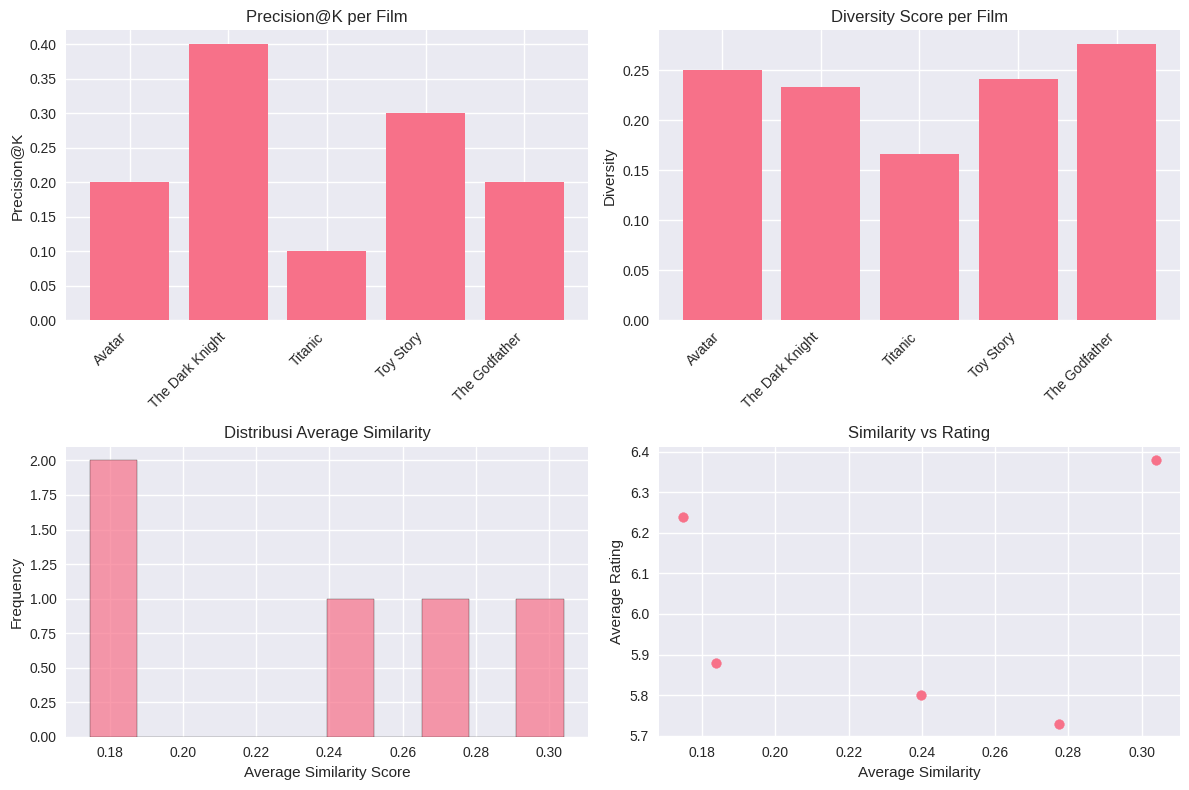

In [18]:
print("\n" + "=" * 50)
print("TESTING SISTEM REKOMENDASI")
print("=" * 50)

# Daftar film untuk testing (berbagai genre)
test_movies = [
    'Avatar',                    # Sci-fi/Action
    'The Dark Knight',          # Action/Crime
    'Titanic',                  # Romance/Drama
    'Toy Story',               # Animation/Family
    'The Godfather',           # Crime/Drama
    'Pulp Fiction',            # Crime/Thriller
    'The Lion King',           # Animation/Family
    'Forrest Gump',            # Drama/Romance
    'The Matrix',              # Sci-fi/Action
    'Finding Nemo'             # Animation/Family
]

# Filter film yang ada dalam dataset
available_test_movies = [movie for movie in test_movies if movie in indices.index]
print(f"📋 Film test yang tersedia: {len(available_test_movies)}/{len(test_movies)}")
print(f"Film: {available_test_movies}")

# Contoh rekomendasi detail
print(f"\n🎬 CONTOH REKOMENDASI UNTUK '{available_test_movies[0]}':")
sample_recs = get_movie_recommendations(available_test_movies[0], top_n=5, min_similarity=0.1)
if not sample_recs.empty:
    print(sample_recs.to_string(index=False))
else:
    print("Tidak ada rekomendasi yang memenuhi kriteria.")

# Evaluasi sistem
print(f"\n📊 EVALUASI SISTEM:")
evaluation_results = evaluate_system(available_test_movies[:5], top_n=10)

if not evaluation_results.empty:
    print("\nHASIL EVALUASI:")
    print(evaluation_results.round(4).to_string(index=False))

    # Summary statistics
    print(f"\n📈 RINGKASAN PERFORMA:")
    print(f"Average Precision@K: {evaluation_results['precision@k'].mean():.3f}")
    print(f"Average Diversity: {evaluation_results['diversity'].mean():.3f}")
    print(f"Average Novelty: {evaluation_results['novelty'].mean():.3f}")
    print(f"Average Similarity: {evaluation_results['avg_similarity'].mean():.3f}")
    print(f"Average Rating of Recommendations: {evaluation_results['avg_rating'].mean():.1f}")

# Visualisasi hasil evaluasi
if not evaluation_results.empty and len(evaluation_results) > 1:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # Precision@K
    axes[0, 0].bar(range(len(evaluation_results)), evaluation_results['precision@k'])
    axes[0, 0].set_title('Precision@K per Film')
    axes[0, 0].set_ylabel('Precision@K')
    axes[0, 0].set_xticks(range(len(evaluation_results)))
    axes[0, 0].set_xticklabels(evaluation_results['movie'], rotation=45, ha='right')

    # Diversity
    axes[0, 1].bar(range(len(evaluation_results)), evaluation_results['diversity'])
    axes[0, 1].set_title('Diversity Score per Film')
    axes[0, 1].set_ylabel('Diversity')
    axes[0, 1].set_xticks(range(len(evaluation_results)))
    axes[0, 1].set_xticklabels(evaluation_results['movie'], rotation=45, ha='right')

    # Similarity Distribution
    axes[1, 0].hist(evaluation_results['avg_similarity'], bins=10, edgecolor='black', alpha=0.7)
    axes[1, 0].set_title('Distribusi Average Similarity')
    axes[1, 0].set_xlabel('Average Similarity Score')
    axes[1, 0].set_ylabel('Frequency')

    # Rating vs Similarity
    axes[1, 1].scatter(evaluation_results['avg_similarity'], evaluation_results['avg_rating'])
    axes[1, 1].set_title('Similarity vs Rating')
    axes[1, 1].set_xlabel('Average Similarity')
    axes[1, 1].set_ylabel('Average Rating')

    plt.tight_layout()
    plt.show()

Bagian ini menyediakan antarmuka interaktif berbasis terminal yang memungkinkan pengguna untuk mencoba sistem rekomendasi secara langsung. Fungsi `recommend_movies_interactive()` memungkinkan pengguna untuk memasukkan judul film, menentukan jumlah rekomendasi yang diinginkan, dan menetapkan skor kemiripan minimum (*minimum similarity score*).

**Alur kerja fungsi ini sebagai berikut:**

1. Sistem menampilkan jumlah film yang tersedia dalam database.
2. Pengguna diminta memasukkan judul film sebagai referensi rekomendasi.
3. Jika input adalah `'quit'`, maka sistem akan keluar dari mode interaktif.
4. Pengguna juga bisa menentukan:
   - Berapa banyak film yang ingin direkomendasikan (default = 5)
   - Nilai minimum dari skor kemiripan (default = 0.1)
5. Sistem kemudian memanggil fungsi `get_movie_recommendations()` dengan parameter tersebut untuk menghasilkan daftar film yang relevan.
6. Hasil rekomendasi ditampilkan satu per satu, mencakup:
   - Judul dan tahun rilis
   - Rating rata-rata
   - Skor kemiripan
   - Genre film


In [19]:
def recommend_movies_interactive():
    """
    Fungsi interaktif untuk mendapatkan rekomendasi
    """
    print("\n" + "🎬" * 20)
    print("SISTEM REKOMENDASI FILM INTERAKTIF")
    print("🎬" * 20)

    while True:
        print(f"\nJumlah film dalam database: {len(movies_df)}")
        movie_title = input("\nMasukkan judul film (atau 'quit' untuk keluar): ").strip()

        if movie_title.lower() == 'quit':
            print("Terima kasih telah menggunakan sistem rekomendasi!")
            break

        if not movie_title:
            print("❌ Silakan masukkan judul film.")
            continue

        try:
            num_recs = int(input("Berapa jumlah rekomendasi yang diinginkan? (default: 5): ") or "5")
            min_sim = float(input("Minimum similarity score? (0.0-1.0, default: 0.1): ") or "0.1")
        except ValueError:
            print("❌ Input tidak valid. Menggunakan nilai default.")
            num_recs = 5
            min_sim = 0.1

        print(f"\n🔍 Mencari rekomendasi untuk '{movie_title}'...")
        recommendations = get_movie_recommendations(movie_title, num_recs, min_sim)

        if not recommendations.empty:
            print(f"\n✅ Ditemukan {len(recommendations)} rekomendasi:")
            print("-" * 80)

            for idx, row in recommendations.iterrows():
                print(f"{idx+1}. {row['title_x']} ({row['release_year']})")
                print(f"   Rating: {row['vote_average']:.1f} | Similarity: {row['similarity_score']:.3f}")
                print(f"   Genres: {', '.join(row['genres']) if row['genres'] else 'N/A'}")
                print()
        else:
            print("❌ Tidak ditemukan rekomendasi yang memenuhi kriteria.")

        print("-" * 80)

In [20]:
print("\n" + "=" * 50)
print("KESIMPULAN DAN INSIGHT")
print("=" * 50)

print("""
📊 RINGKASAN SISTEM:
✅ Berhasil membangun Content-Based Filtering system
✅ Menggunakan fitur: genres, keywords, cast, director
✅ Implementasi TF-IDF Vectorizer untuk feature extraction
✅ Cosine Similarity untuk menghitung kemiripan film
✅ Sistem evaluasi dengan multiple metrics

🎯 KELEBIHAN SISTEM:
- Dapat memberikan rekomendasi tanpa data rating pengguna
- Recommendations based on content similarity
- Scalable untuk dataset besar
- Dapat menjelaskan alasan rekomendasi (explainable AI)

⚠️  LIMITASI SISTEM:
- Terbatas pada fitur konten yang tersedia
- Tidak mempertimbangkan preferensi personal pengguna
- Rentan terhadap over-specialization
- Membutuhkan preprocessing yang intensif

🚀 FUTURE IMPROVEMENTS:
- Implementasi Hybrid Filtering (Content + Collaborative)
- Penambahan fitur sentiment analysis dari overview
- Integration dengan user behavior data
- Real-time recommendation updates
""")

# Coverage analysis
total_movies_original = len(movies_df)
movies_with_recs = len(movies_df[movies_df['soup'].str.len() > 5])
coverage_rate = movies_with_recs / total_movies_original

print(f"\n📈 COVERAGE SISTEM:")
print(f"Total film yang dapat direkomendasikan: {movies_with_recs}/{total_movies_original}")
print(f"Coverage Rate: {coverage_rate:.1%}")

# Uncomment the line below to run interactive mode
# recommend_movies_interactive()

print("\n🎉 Sistem rekomendasi film telah siap digunakan!")
print("📧 Gunakan fungsi get_movie_recommendations(title, top_n, min_similarity) untuk mendapatkan rekomendasi.")


KESIMPULAN DAN INSIGHT

📊 RINGKASAN SISTEM:
✅ Berhasil membangun Content-Based Filtering system
✅ Menggunakan fitur: genres, keywords, cast, director
✅ Implementasi TF-IDF Vectorizer untuk feature extraction
✅ Cosine Similarity untuk menghitung kemiripan film
✅ Sistem evaluasi dengan multiple metrics

🎯 KELEBIHAN SISTEM:
- Dapat memberikan rekomendasi tanpa data rating pengguna
- Recommendations based on content similarity
- Scalable untuk dataset besar
- Dapat menjelaskan alasan rekomendasi (explainable AI)

⚠️  LIMITASI SISTEM:
- Terbatas pada fitur konten yang tersedia
- Tidak mempertimbangkan preferensi personal pengguna
- Rentan terhadap over-specialization
- Membutuhkan preprocessing yang intensif

🚀 FUTURE IMPROVEMENTS:
- Implementasi Hybrid Filtering (Content + Collaborative)
- Penambahan fitur sentiment analysis dari overview
- Integration dengan user behavior data
- Real-time recommendation updates


📈 COVERAGE SISTEM:
Total film yang dapat direkomendasikan: 4790/4790
Covera